# 04 - Random Forest
**Owner:** Sriniket Deeduvanu

A random forest is an ensemble of decision trees. Each tree is trained on a bootstrap sample of the training buildings and considers only a random subset of the features at every split. The forest predicts the damage grade by majority vote of its trees. Averaging many decorrelated trees reduces the variance (overfitting) of a single deep tree while keeping the ability to model non-linear relationships and feature interactions.

**Design decisions**
- Inputs come from `build_tree_preprocessor`: ordinal-encoded categoricals, the raw `age` and all three geo IDs as plain numbers. Trees split on thresholds, so no scaling is needed and the extreme `age` values do not matter (see notebook 01).
- The selection metric is validation micro-F1, the project metric.
- Eight configurations are compared, varying the number of trees (`n_estimators`), the tree depth (`max_depth`), the minimum samples per leaf (`min_samples_leaf`) and the class weighting (`class_weight`). The first six form the initial search. The last two extend it towards smaller leaves and more trees, because the best of the first six used the smallest leaf size that had been tested.
- `class_weight="balanced"` is included to test a trade-off: it gives more weight to the rare grade 1 class, which can raise its recall but can also lower overall accuracy and therefore micro-F1.
- Training and validation micro-F1 are reported for every configuration to show how much each one overfits.
- Permutation importance (5 repeats on 5,000 validation buildings) is computed for the selected model and saved to `results/metrics/` for the comparison notebook.

In [1]:
import os, sys
from pathlib import Path

# --- Colab only: clone the repo and move into it ---
REPO = "ML-Project-Earthquake-Damage"
GITHUB_URL = "https://github.com/ayaanGH06/ML-Project-Earthquake-Damage.git"  # private repo: use a token URL in Colab, never commit it

if "google.colab" in sys.modules and not os.path.exists("src"):
    if not os.path.exists(REPO):
        !git clone {GITHUB_URL}
    %cd {REPO}
    !pip install -q -r requirements.txt

# --- Local Jupyter: notebooks run from notebooks/, so go up to the repo root ---
if Path.cwd().name == "notebooks":
    os.chdir("..")

# --- Data: the 3 CSVs must be in data/raw/ (see README for the download link) ---
DATA_DIR = Path("data/raw")
needed = ["train_values.csv", "train_labels.csv", "test_values.csv"]
missing = [f for f in needed if not (DATA_DIR / f).exists()]
if missing:
    raise FileNotFoundError(
        f"Missing {missing} in {DATA_DIR.resolve()}. "
        "Download them from the Google Drive link in the README and place them in data/raw/."
    )

from src.data import load_raw, train_val_split, build_scaled_preprocessor, build_tree_preprocessor
from src.evaluate import evaluate_model, micro_f1

X, y, X_test = load_raw(DATA_DIR)
X_train, X_val, y_train, y_val = train_val_split(X, y)
print(X_train.shape, X_val.shape)

(208480, 38) (52121, 38)


## 1. Hyperparameter search

In [2]:
import json
import time
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
from sklearn.pipeline import Pipeline
from src.evaluate import save_permutation_importance

METRIC_DIR = Path("results/metrics")
METRIC_DIR.mkdir(parents=True, exist_ok=True)

configs = [
    {"name": "Baseline", "n_estimators": 100, "max_depth": None, "min_samples_leaf": 5, "class_weight": None},
    {"name": "Shallower", "n_estimators": 100, "max_depth": 20, "min_samples_leaf": 5, "class_weight": None},
    {"name": "More trees", "n_estimators": 200, "max_depth": None, "min_samples_leaf": 5, "class_weight": None},
    {"name": "Smaller leaves", "n_estimators": 100, "max_depth": None, "min_samples_leaf": 2, "class_weight": None},
    {"name": "Balanced weights", "n_estimators": 100, "max_depth": None, "min_samples_leaf": 5, "class_weight": "balanced"},
    {"name": "Shallow + balanced", "n_estimators": 200, "max_depth": 20, "min_samples_leaf": 4, "class_weight": "balanced"},
    {"name": "Smallest leaves", "n_estimators": 100, "max_depth": None, "min_samples_leaf": 1, "class_weight": None},
    {"name": "Leaf 2, more trees", "n_estimators": 300, "max_depth": None, "min_samples_leaf": 2, "class_weight": None},
]

results = []
best_model, best_config, best_f1 = None, None, -1

for config in configs:
    t0 = time.time()
    model = Pipeline([
        ("preprocessor", build_tree_preprocessor(X_train)),
        ("classifier", RandomForestClassifier(
            n_estimators=config["n_estimators"],
            max_depth=config["max_depth"],
            min_samples_leaf=config["min_samples_leaf"],
            class_weight=config["class_weight"],
            random_state=42,
            n_jobs=-1,
        )),
    ])
    model.fit(X_train, y_train)
    train_f1 = f1_score(y_train, model.predict(X_train), average="micro")
    val_pred = model.predict(X_val)
    val_f1 = f1_score(y_val, val_pred, average="micro")
    results.append({
        "configuration": config["name"],
        "n_estimators": config["n_estimators"],
        "max_depth": config["max_depth"],
        "min_samples_leaf": config["min_samples_leaf"],
        "class_weight": config["class_weight"],
        "train_micro_f1": train_f1,
        "val_micro_f1": val_f1,
        "val_macro_f1": f1_score(y_val, val_pred, average="macro"),
        "seconds": round(time.time() - t0),
    })
    print(f"{config['name']:>20}: train {train_f1:.4f} | val {val_f1:.4f} | {results[-1]['seconds']} s")
    if val_f1 > best_f1:
        best_model, best_config, best_f1 = model, config, val_f1

results_df = pd.DataFrame(results).sort_values("val_micro_f1", ascending=False).reset_index(drop=True)
print()
display(results_df.round(4))
print("Selected configuration:", best_config)

            Baseline: train 0.7812 | val 0.7239 | 7 s
           Shallower: train 0.7408 | val 0.7068 | 6 s
          More trees: train 0.7824 | val 0.7251 | 11 s
      Smaller leaves: train 0.8673 | val 0.7307 | 6 s
    Balanced weights: train 0.7412 | val 0.6743 | 6 s
  Shallow + balanced: train 0.7064 | val 0.6632 | 12 s
     Smallest leaves: train 0.9868 | val 0.7234 | 8 s
  Leaf 2, more trees: train 0.8685 | val 0.7314 | 22 s



,configuration,n_estimators,max_depth,min_samples_leaf,class_weight,train_micro_f1,val_micro_f1,val_macro_f1,seconds
0,"Leaf 2, more trees",300,NaN,2,NaN,0.8685,0.7314,0.6645,22
1,Smaller leaves,100,NaN,2,NaN,0.8673,0.7307,0.6647,6
2,More trees,200,NaN,5,NaN,0.7824,0.7251,0.6518,11
3,Baseline,100,NaN,5,NaN,0.7812,0.7239,0.6499,7
4,Smallest leaves,100,NaN,1,NaN,0.9868,0.7234,0.6674,8
5,Shallower,100,20.0,5,NaN,0.7408,0.7068,0.6264,6
6,Balanced weights,100,NaN,5,balanced,0.7412,0.6743,0.6502,6
7,Shallow + balanced,200,20.0,4,balanced,0.7064,0.6632,0.6414,12


Selected configuration: {'name': 'Leaf 2, more trees', 'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 2, 'class_weight': None}


The configurations fall into three groups. Limiting the trees hurts: capping the depth at 20 lowers validation micro-F1 from 0.7239 (baseline) to 0.7068, and the depth-limited balanced configuration is the weakest at 0.6632. Class weighting also costs accuracy: the balanced variant of the baseline drops from 0.7239 to 0.6743 while its macro-F1 is unchanged (0.6502 against 0.6499), which means the weighting moves errors between classes rather than reducing them. Letting the trees fit the data more closely helps up to a point: reducing `min_samples_leaf` from 5 to 2 raises validation micro-F1 to 0.7307 (training: 0.8673), whereas leaves of size 1 overfit almost completely (training 0.9868) and fall back to 0.7234. Adding trees then gives only a small gain (0.7314 with 300 trees against 0.7307 with 100).

The selected configuration is therefore 300 trees, no depth limit, `min_samples_leaf = 2` and no class weighting, with a validation micro-F1 of 0.7314.

## 2. Selected model: evaluation and feature importance
The selected configuration is evaluated on the validation split with the shared `evaluate_model`, which saves the confusion matrix and the metrics used by the comparison notebook.

random_forest: micro-F1 = 0.7314
              precision    recall  f1-score   support

           1       0.69      0.45      0.54      5025
           2       0.72      0.86      0.79     29652
           3       0.77      0.59      0.67     17444

    accuracy                           0.73     52121
   macro avg       0.72      0.63      0.66     52121
weighted avg       0.73      0.73      0.72     52121



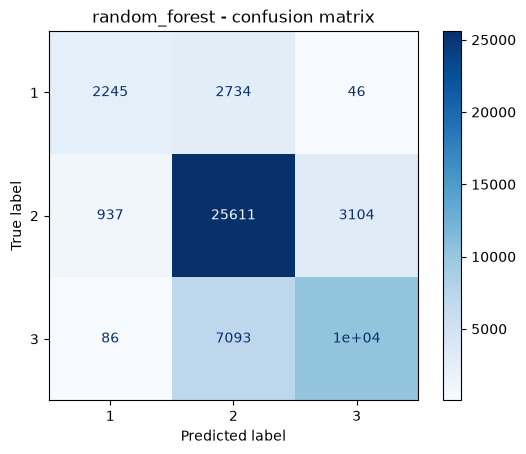

Training micro-F1:   0.8685
Validation micro-F1: 0.7314
Train - validation gap: 0.1371

Top 10 features by permutation importance (5,000 validation rows, 5 repeats):
geo_level_1_id                         0.1415
geo_level_2_id                         0.0379
has_superstructure_mud_mortar_stone    0.0259
geo_level_3_id                         0.0200
roof_type                              0.0136
has_superstructure_timber              0.0126
area_percentage                        0.0123
height_percentage                      0.0120
ground_floor_type                      0.0114
age                                    0.0097


In [3]:
y_val_pred_rf = best_model.predict(X_val)
rf_f1 = evaluate_model("random_forest", y_val, y_val_pred_rf)

best_row = results_df.iloc[0]
print(f"Training micro-F1:   {best_row['train_micro_f1']:.4f}")
print(f"Validation micro-F1: {best_row['val_micro_f1']:.4f}")
print(f"Train - validation gap: {best_row['train_micro_f1'] - best_row['val_micro_f1']:.4f}")

with open(METRIC_DIR / "random_forest_params.json", "w") as f:
    json.dump({"configuration": best_config,
               "train_micro_f1": float(best_row["train_micro_f1"]),
               "val_micro_f1": float(best_row["val_micro_f1"])}, f, indent=2)
results_df.to_json(METRIC_DIR / "random_forest_tuning.json", orient="records", indent=2)

fi = save_permutation_importance("random_forest", best_model, X_val, y_val)
top = pd.Series(fi["importance_mean"]).nlargest(10)
print(f"\nTop 10 features by permutation importance ({fi['n_rows']:,} validation rows, {fi['n_repeats']} repeats):")
print(top.round(4).to_string())

The selected forest reaches a validation micro-F1 of 0.7314, about 0.16 above the majority-class baseline (0.5689), 0.034 above the neural network and 0.051 above KNN. Its training micro-F1 is 0.8685, a gap of 0.137 to validation, so the forest overfits clearly; this is the price of the small leaves that gave the best validation score. Part of the benefit of small leaves may also come from memorising buildings whose features exactly repeat in the training split (6.2% of training rows repeat the features of an earlier building, see notebook 01), so the validation score may be somewhat optimistic for this model.

Like the other models it is best on grade 2 (recall 0.86) and weakest on grade 1 (recall 0.45; grade 3: 0.59). Its precision on grades 1 and 3 (0.69 and 0.77) is higher than that of KNN (0.60 and 0.69) and the neural network (0.62 and 0.70).

By permutation importance the most important feature, by a wide margin, is `geo_level_1_id` (a drop in micro-F1 of about 0.14 when it is shuffled), followed by `geo_level_2_id` (0.038), `has_superstructure_mud_mortar_stone` (0.026) and `geo_level_3_id` (0.020). The three location columns therefore carry most of the signal, followed by building material, roof type and building size. Because KNN and the neural network cannot use `geo_level_2_id` and `geo_level_3_id`, this is likely to explain part of their gap to the forest.